# 데이터과학 01차시 — 데이터 과학 문제 해결과 NumPy 배열

**교과 연계: **Ⅰ-01** · 성취기준: **[12데과01-01]**

## 학습 목표
- 배열로 과학 측정값의 특성을 요약한다.
- 분석 결과를 코드 출력만으로 끝내지 않고, **자료의 의미·한계·의사결정 가능성**까지 해석한다.

**핵심 키워드:** `데이터 과학 문제 해결 6단계`, `np.array`, `shape, dtype`, `mean, std`

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path    # 파이썬의 내장 모듈인 pathlib에서 Path라는 특정 기능(클래스)만 콕 집어서 가져오겠다는 의미

####그래프의 기본 크기와 데이터프레임의 출력 방식을 설정합니다.

- plt.rcParams: Matplotlib 그래프의 전역 설정(기본값)을 변경하는 딕셔너리. 여기서는 그래프의 가로 크기를 7인치, 세로 크기를 4인치로 고정함.

- pd.set_option(옵션명, 값): Pandas의 화면 출력 기본값을 변경. display.max_columns를 50으로 설정하여, 열(Column)이 많은 데이터를 화면에 출력할 때 중간이 생략되지 않고 최대 50개 열까지 한 번에 보이도록 함.

In [ ]:
plt.rcParams['figure.figsize'] = (7, 4)
pd.set_option('display.max_columns', 50)

####데이터 경로에 관한 코드 설명
- 데이터 파일이 있을 만한 여러 폴더(경로)를 미리 지정해 두고, 파일명만 입력하면 알아서 해당 파일이 존재하는 진짜 경로를 찾아주는 편리한 함수.

- DATA_CANDIDATES 리스트: 데이터가 존재할 가능성이 있는 후보 경로들을 Path 객체로 담아둔 리스트
- ../03_예제데이터: 현재 폴더의 상위 폴더에 있는 예제데이터 폴더
- 03_예제데이터: 현재 폴더 내에 있는 예제데이터 폴더
- /content: 구글 코랩(Colab)의 기본 작업 공간
- .: 현재 파이썬 스크립트가 실행되는 현재 폴더
- def data_path(filename):: filename(찾고자 하는 파일명)을 입력받는 함수를 정의.
- p = d / filename: pathlib.Path의 강력한 기능. 슬래시(/) 기호를 이용해 폴더 경로와 파일명을 자연스럽게 이어붙여줌.
(예: /content + data.csv = /content/data.csv)
- if p.exists(): return p: 조합된 경로에 실제로 파일이 존재하면(exists()), 그 경로를 반환(return)하고 함수를 종료.
- raise FileNotFoundError(...): 후보 경로를 모두 찾아봤는데도 파일이 없다면 에러를 강제로 발생(raise)시킴.

💡 요약:
이 코드를 맨 위에 실행해 두면, 이후에 데이터를 불러올 때 pd.read_csv(data_path('data.csv')) 처럼 작성할 수 있다. 이렇게 하면 내 컴퓨터에서 실행하든, 다른 사람의 컴퓨터에서 실행하든, 코랩에서 실행하든 경로 수정 없이 코드가 똑같이 작동하게 된다.

## 해당 코드 자체는 매우 중요한 것은 아니, 데이터셋 파일을 불러올 때, 오류를 예방하기 위해 작성한 코드라고 생각하면 됨.

In [ ]:
DATA_CANDIDATES = [Path('../03_예제데이터'), Path('03_예제데이터'), Path('/content'), Path('.')]
def data_path(filename):
    for d in DATA_CANDIDATES:
        p = d / filename
        if p.exists():
            return p
    raise FileNotFoundError(f'{filename}을 찾을 수 없습니다. Colab에서는 해당 CSV를 /content에 업로드하세요.')

In [ ]:
# 관측치(예: 중력 가속도 데이터 등)가 담긴 파이썬 리스트를 고속 연산이 가능한 NumPy 배열(array)로 생성
measurements = np.array([9.81, 9.78, 9.84, 9.80, 9.83, 9.79])

# 생성된 배열의 전체 데이터를 화면에 출력
print(measurements)

# measurements.shape: 배열의 형태(데이터의 개수 및 차원, 여기서는 1차원 데이터 6개이므로 (6,) 반환)
# measurements.dtype: 배열 안 데이터의 자료형(여기서는 실수형인 float64 반환)
print('shape=', measurements.shape, 'dtype=', measurements.dtype)

# measurements.mean(): 데이터들의 평균값을 계산
# measurements.std(ddof=1): 데이터들의 '표본 표준편차'를 계산
# └─ ddof=1 (Delta Degrees of Freedom) 옵션은 자유도를 n-1로 설정하여, 전체 모집단이 아닌 '표본'의 표준편차를 정확히 구할 때 사용함
# numpy에서 ddof는 자유도 보정(Delta Degrees of Freedom)을 의미함.
print('mean=', measurements.mean(), 'std=', measurements.std(ddof=1))

[9.81 9.78 9.84 9.8  9.83 9.79]
shape= (6,) dtype= float64
mean= 9.808333333333334 std= 0.023166067138525627


### 스스로 탐구하여 이해해보기
### 질문: numpy의 표준편차 계산시 옵션은 ddof=0과 ddof=1 두 가지가 있다. 두 옵션의 차이를 설명하고, 이를 이해할 수 있는 데이터 예시와 결과를 출력하여 확인하는 코드를 작성해보자.

In [ ]:
# 탐구활동 코드를 직접 작성하시오.

print('mean=', measurements.mean(), 'std=', measurements.std(ddof=0))

'''
ddof=0: 분모가 N이 됩니다. 전체 데이터(모집단)를 전부 다 가지고 있을 때 사용합니다.
ddof=1: 분모가 N - 1이 됩니다. 전체 중 일부(표본)를 뽑아서 전체를 추정할 때 사용합니다
'''

mean= 9.808333333333334 std= 0.021147629234082737


'\nddof=0: 분모가 N이 됩니다. 전체 데이터(모집단)를 전부 다 가지고 있을 때 사용합니다.\nddof=1: 분모가 N - 1이 됩니다. 전체 중 일부(표본)를 뽑아서 전체를 추정할 때 사용합니다\n'

##### [추가 질문-스스로 찾아서 답을 만들기] Pandas에도 표준편차를 구하는 함수가 있다. 이 함수에도 numpy처럼 옵션이 있을까? 어떤 방식으로 계산이 될까?

### 실습 1. 측정값을 배열로 표현하고 요약하기
다음 측정값의 평균, 최댓값, 최솟값, 표준편차를 계산하세요.

In [ ]:
x = np.array([12.4, 12.8, 11.9, 12.6, 12.2, 12.7])
# TODO: 평균/최댓값/최솟값/표준편차를 출력하세요.
series = pd.Series(x)
print(series)
y = series.describe()
print([float(y['mean']), float(y['max']), float(y['min']), float(y['std'])])

0    12.4
1    12.8
2    11.9
3    12.6
4    12.2
5    12.7
dtype: float64
[12.433333333333335, 12.8, 11.9, 0.33862466931200785]


In [ ]:
x = np.array([12.4, 12.8, 11.9, 12.6, 12.2, 12.7])
# TODO: 평균/최댓값/최솟값/표준편차를 출력하세요.
print('mean', x.mean())
print('max', x.max())
print('min', x.min())
print('std', x.std())

mean 12.433333333333335
max 12.8
min 11.9
std 0.30912061651652345


### 실습 2. 문제 해결 6단계 연결
아래 분석 과제를 6단계(문제 정의→수집→전처리·탐색→모델링→평가→활용)에 대응시키세요. 코드 셀에는 단계 이름을 리스트로 작성하세요.

In [ ]:
steps = [
    # TODO
]
steps

## 🚀 심화 탐구 과제 — 측정 데이터의 신뢰성
1. 같은 물리량을 30회 측정했다고 가정하여 난수를 생성하고 평균과 표준편차가 표본 크기에 따라 어떻게 안정되는지 비교하세요.
2. 표본 수 n=5, 10, 30일 때 평균의 변동성이 어떻게 달라지는지 100회 반복 실험으로 확인하세요.


이게 100회 실험에 대한 표본 평균들의 표준 편차를 알아야 함

**제출 형식 권장:** 분석 질문 1문장 → 코드/그래프 → 수치 근거 → 3~5문장 해석 → 한계 또는 후속 질문

In [ ]:
!pip install koreanize_matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 57.8 MB/s eta 0:00:00


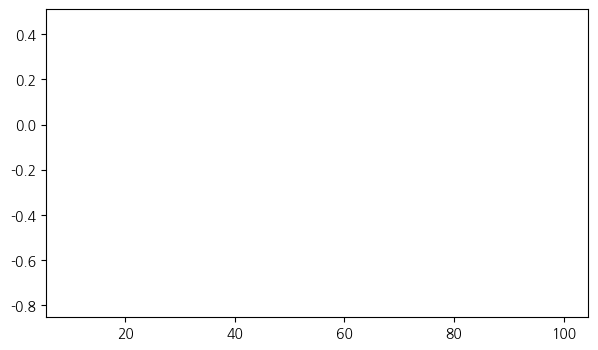

In [41]:

import matplotlib.pyplot as plt

np.random.seed(42)

mean = 0

std = 1

test = [10, 30, 50, 100]
result = []


index = []

for i in range(4):
  for j in range(1, 101):
    result.append(np.random.normal(mean, std, test[i]).mean())

for i in range(4):
  plt.plot(test[i], result[i], 'b-')
plt.show()


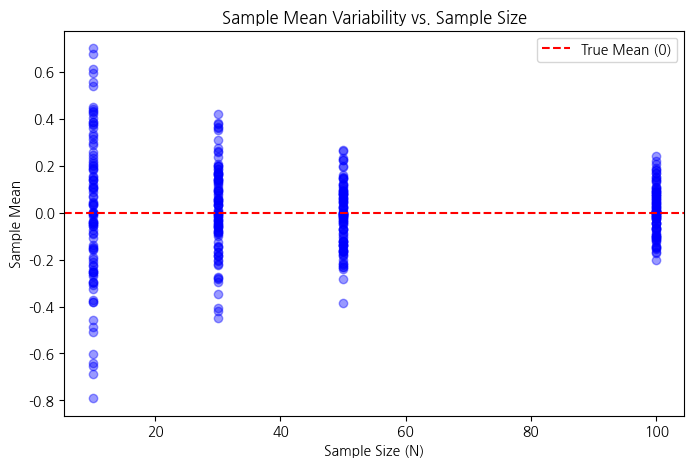

In [42]:
import matplotlib.pyplot as plt
import numpy as np

np.random.seed(42)

mean = 0
std = 1
test = [10, 30, 50, 100]

plt.figure(figsize=(8, 5))

for n in test:
    # 샘플 크기가 n일 때 100번의 표본평균 계산
    means = [np.random.normal(mean, std, n).mean() for _ in range(100)]

    # x축 좌표를 n으로 고정하여 100개의 점을 산점도로 표현
    plt.scatter([n] * 100, means, alpha=0.4, color='blue')

plt.axhline(0, color='red', linestyle='--', label='True Mean (0)')
plt.xlabel('Sample Size (N)')
plt.ylabel('Sample Mean')
plt.title('Sample Mean Variability vs. Sample Size')
plt.legend()
plt.show()

/tmp/ipykernel_867/321388294.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(results, labels=test)


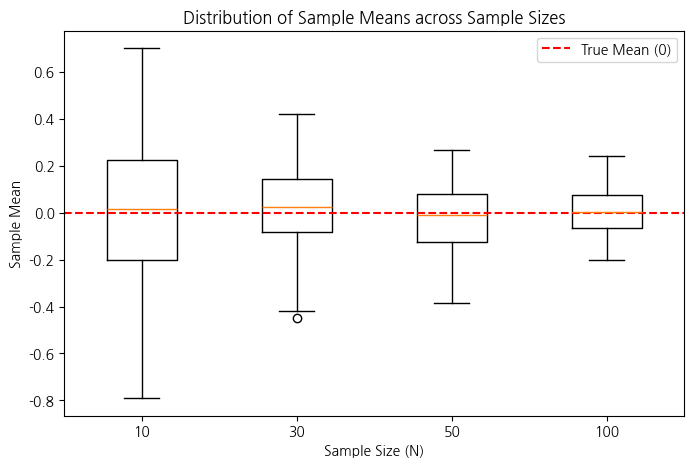

In [43]:
import matplotlib.pyplot as plt
import numpy as np

np.random.seed(42)

mean = 0
std = 1
test = [10, 30, 50, 100]

# 각 샘플 크기별 결과를 2차원 리스트로 저장
results = []
for n in test:
    means = [np.random.normal(mean, std, n).mean() for _ in range(100)]
    results.append(means)

plt.figure(figsize=(8, 5))
plt.boxplot(results, labels=test)
plt.axhline(0, color='red', linestyle='--', label='True Mean (0)')
plt.xlabel('Sample Size (N)')
plt.ylabel('Sample Mean')
plt.title('Distribution of Sample Means across Sample Sizes')
plt.legend()
plt.show()

## 실습 정리
- 오늘 사용한 핵심 함수/개념 3개를 적으세요.
- 오늘의 분석에서 **가장 중요한 선택 한 가지와 그 이유**를 적으세요.
- 출력된 수치 또는 그래프 중 결론을 뒷받침하는 근거를 1개 제시하세요.